# clock/16 — the move-on (decision) signal, on its own

Every result we have about the move-on signal so far is a by-product of a dissociation against
something else (`09` vs gaze/goalscope, `09.1` vs goal-head gaze, `11` vs goal heads). This notebook
evaluates the signal **on its own terms**, on the setup where sub-steps are *independent* — the
`check_conditions` multiline corpus. The nested (sub-sub-step) case is deliberately out of scope.

**What is already established** (`11 §4`, N=256, α=2.0, pivot −2): transplanting the mean move-on
activation into the *decision* heads takes the move-on rate from **0.047 → 0.977**, hard-flip 0.975,
while the same vector through *goal* heads only reaches 0.152. One aggregate vector, causal.

Two caveats that shape this notebook:

* that oracle checks the **variable letter**, not the implementation — "the pointer advanced", not
  "the right instruction was fetched" (§3 closes this);
* `cur = randint(1, N_COND-2)` is inclusive, so the transitions sampled were **b→c, c→d, d→e**;
  `a→b` was never in it. `a` is reserved to establish that multiline implementations are allowed,
  so we keep excluding it.

### Plan

| § | question | scale |
|---|---|---|
| 1 | is it **one** vector, or one per transition? | affinity only, no re-run |
| 1.1 | does a vector cached on `a,b,c…` transfer to `p,q,r…` / `var_1,var_2…`? | scaled |
| 1.2 | natural names, and reverse execution order | qualitative |
| 2 | `next()` or program counter — does a bigger α skip further? | qualitative |
| 3 | does the *fetch* happen — is the content right, not just the label? | measure choice |

**Framing.** The working analogy is `next()` on an iterator, not a program counter: the signal is
content-agnostic and advance-only, and the *destination content* is resolved afterwards. §1.1 is the
sharpest test of that — a vector cached on `a,b,c` contexts should, if it means "advance in the
demonstrated sequence", produce `q` after `p`. If it instead pushes toward `b`, the signal is partly
about letter identity and the analogy is wrong.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, json, random, logging
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "2,3,4")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from rich.console import Console
from rich.theme import Theme
from rich.table import Table
from rich.panel import Panel
from rich.markup import escape
from src.utils import logging_utils, env_utils

logging_utils.configure(level=logging.WARNING)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)
RES = env_utils.DEFAULT_RESULTS_DIR

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
N_LAYER, N_HEADS = mt.n_layer, mt.model.config.num_attention_heads
print(f"n_layer={N_LAYER}  n_heads={N_HEADS}  n_embd={mt.n_embd}")

2026-08-10 14:50:46 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

n_layer=64  n_heads=40  n_embd=5120


In [3]:
# ── decision heads + the patch config (same as 11 §1, so numbers stay comparable) ──
from src.goals.head_loc_attn import HeadMask, forward_with_src_replacement, get_o_proj_inputs_batch
from src.goals.oid_gaze import cache_root
from src.tokens import prepare_input

VERSION, COMPLETION_MASK_TAG, SEL_THRESHOLD = "conditions", "lam10.0", 0.8
_root = os.path.join(cache_root(MODEL_NAME, VERSION), "completion_mask")
_cand = [t for t in os.listdir(_root) if os.path.isdir(os.path.join(_root, t)) and COMPLETION_MASK_TAG in t]
assert _cand, f"no completion_mask with tag {COMPLETION_MASK_TAG!r} under {_root}"
_latest = max(_cand, key=lambda t: os.path.getmtime(os.path.join(_root, t)))
DCK = torch.load(os.path.join(_root, _latest, "mask.pt"), map_location="cpu", weights_only=False)
dec_layers = [int(x) for x in DCK["layers"]]
dmv = DCK["mask_values"].numpy()
decision_heads = [(dec_layers[li], int(h)) for li, h in np.argwhere(dmv > SEL_THRESHOLD)]
PATCH_POS = int(DCK["patch_tokens"][0]) if len(DCK.get("patch_tokens", [-2])) == 1 else -2
ALPHA = 2.0
print(f"decision heads: {len(decision_heads)} (thr {SEL_THRESHOLD}) · layers "
      f"{min(dec_layers)}-{max(dec_layers)} · PATCH_POS={PATCH_POS} · ALPHA={ALPHA}")

def get_mask_bin(heads):
    hm = HeadMask(N_LAYER, N_HEADS)
    with torch.no_grad():
        hm.values.zero_()
        for (l, h) in heads: hm.values[l, h] = 1.0
    return hm

DEC_MASK = get_mask_bin(decision_heads)

decision heads: 181 (thr 0.8) · layers 0-63 · PATCH_POS=-2 · ALPHA=2.0


## 1. One vector, or one per transition?

`11 §4` pooled its sources over all slots, so a single mean vector was shown to be causal *somewhere*
in b→c / c→d / d→e — not that the same thing is being represented at each. Here we cache the signal
**separately per pivot slot** and measure affinity. No re-run of the causal sweep: the existing
0.977 already tells us one pooled vector works.

`build_completion_pairs(..., same=True)` makes the source *be* the destination, so for one slot the
moved-on (`sl_prompt`) and stayed (`ml_prompt`) prompts come from the **same spec** — a true minimal
pair with no content confound.

**Why two matrices.** The vector actually injected is the raw mean of `sl` o_proj inputs (replacement
semantics). But these are un-centred activations with a large shared component, so raw-mean cosines
will read high whether or not the *move-on* part is shared. The contrast
`d[slot] = mean(sl) − mean(stay)` cancels that common part and is the quantity that answers the
question. `‖d‖/‖mean‖` says how much of what we inject is move-on at all.

In [4]:
# ── cache move-on and stay vectors per pivot slot ────────────────────────────
from src.goals.completion_pairs import build_completion_pairs

SLOTS      = [1, 2, 3]            # 1 -> b->c, 2 -> c->d, 3 -> d->e   (a is reserved; see header)
N_SRC      = 256                  # source contexts per slot
SRC_BATCH  = 16
TRANS = {s: f"{chr(97+s)}->{chr(98+s)}" for s in SLOTS}

def mean_at_pivot(prompts, layers, batch=SRC_BATCH):
    """(len(layers), n_embd) mean o_proj input at PATCH_POS over `prompts`."""
    acc = {l: [] for l in layers}
    for i in range(0, len(prompts), batch):
        cache = get_o_proj_inputs_batch(mt, prompts[i:i + batch], layers,
                                        token_positions=[PATCH_POS])
        for l in layers:
            acc[l].append(cache[l][:, 0, :].float().cpu())
    return torch.stack([torch.cat(acc[l], 0).mean(0) for l in layers])

VEC = {}                          # (kind, slot) -> (n_dec_layers, n_embd)
for s in SLOTS:
    pairs = build_completion_pairs(mt, n_pairs=N_SRC, target_slots=(s,), direction="sl->ml",
                                   same=True, patch_tokens=(PATCH_POS,), seed=1234 + s,
                                   log=logger.debug)
    # same=True => source IS dest, so both styles of the SAME spec
    for kind, attr in (("move_on", "sl_prompt"), ("stay", "ml_prompt")):
        VEC[(kind, s)] = mean_at_pivot([getattr(p.source, attr) for p in pairs], dec_layers)
    print(f"slot {s} ({TRANS[s]}): {len(pairs)} contexts")

# the pooled vector, i.e. what 11 §4 injected
VEC[("move_on", "pooled")] = torch.stack([VEC[("move_on", s)] for s in SLOTS]).mean(0)
VEC[("stay",    "pooled")] = torch.stack([VEC[("stay", s)] for s in SLOTS]).mean(0)
print("cached:", sorted({k[0] for k in VEC}), "x", sorted({str(k[1]) for k in VEC}))

slot 1 (b->c): 256 contexts
slot 2 (c->d): 256 contexts
slot 3 (d->e): 256 contexts
cached: ['move_on', 'stay'] x ['1', '2', '3', 'pooled']


  how much of the injected vector is actually 'move-on'?  
┏━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ transition ┃ ‖mean(sl)‖ ┃ ‖d‖ = ‖sl−stay‖ ┃ ‖d‖/‖mean‖ ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ b->c       │     212.82 │          133.71 │      0.628 │
│ c->d       │     211.94 │          127.97 │      0.604 │
│ d->e       │     212.78 │          128.69 │      0.605 │
└────────────┴────────────┴─────────────────┴────────────┘

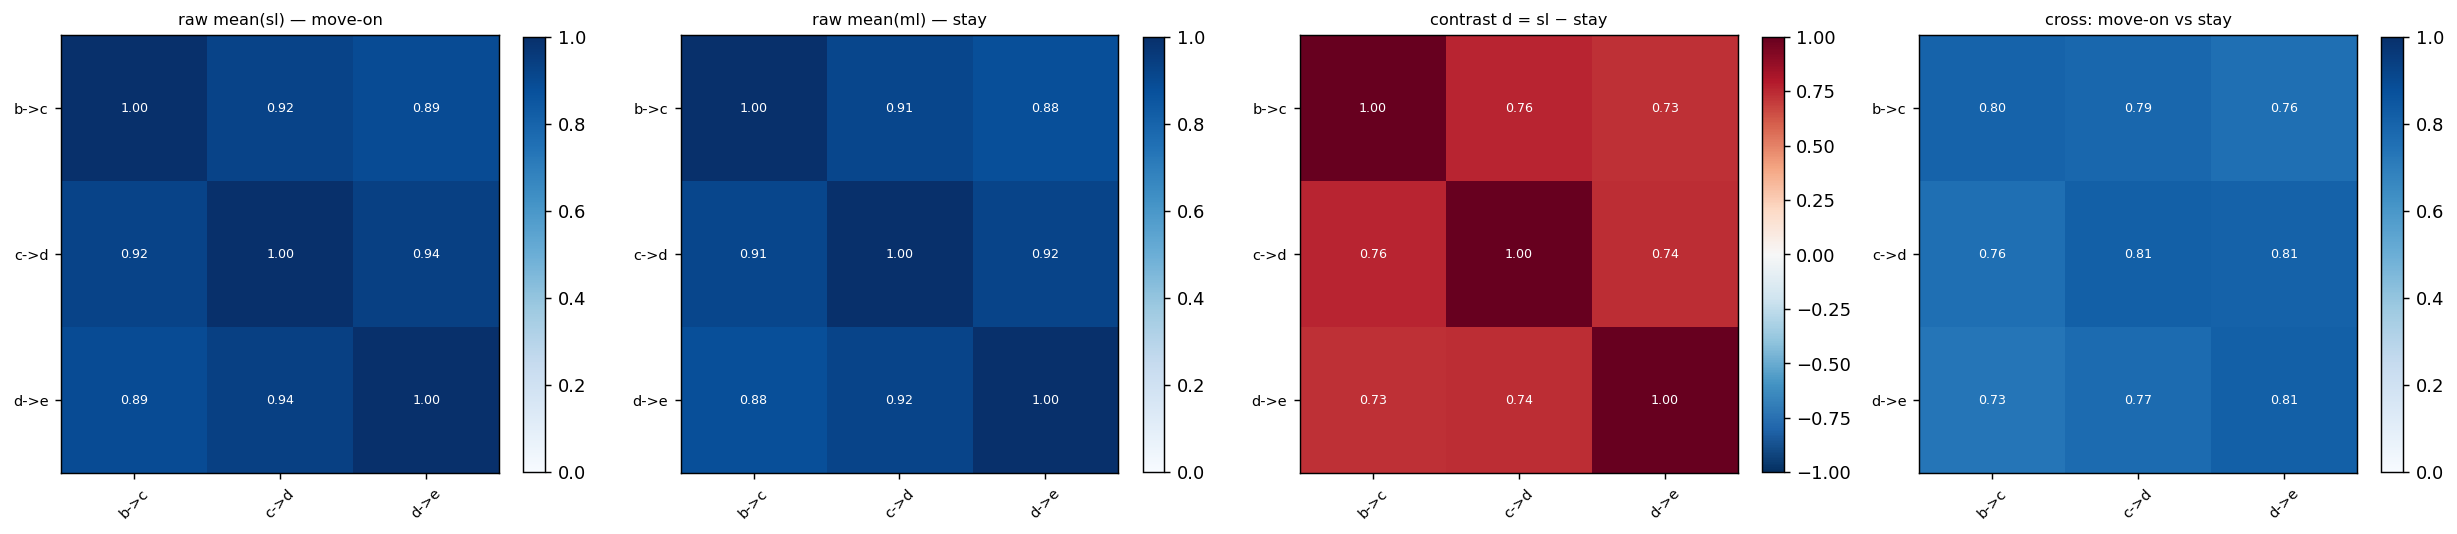

Read the CONTRAST panel. Off-diagonal ≈ diagonal there means the same move-on direction is being represented at 
every transition — one vector, not three. The raw panels are expected to be uniformly high (shared un-centred 
component) and are shown so that is visible rather than mistaken for evidence.

In [5]:
# ── affinity: raw means vs move-on contrasts ────────────────────────────────
def _flat(v): return v.reshape(-1).float()
def cosm(keys, get):
    M = np.zeros((len(keys), len(keys)))
    for i, a in enumerate(keys):
        for j, b in enumerate(keys):
            x, y = _flat(get(a)), _flat(get(b))
            M[i, j] = float(torch.nn.functional.cosine_similarity(x, y, dim=0))
    return M

labels = [TRANS[s] for s in SLOTS]
RAW_ON   = cosm(SLOTS, lambda s: VEC[("move_on", s)])
RAW_STAY = cosm(SLOTS, lambda s: VEC[("stay", s)])
CON      = cosm(SLOTS, lambda s: VEC[("move_on", s)] - VEC[("stay", s)])
# cross-family: is a move-on vector more like another move-on, or like a stay?
CROSS = np.zeros((len(SLOTS), len(SLOTS)))
for i, a in enumerate(SLOTS):
    for j, b in enumerate(SLOTS):
        CROSS[i, j] = float(torch.nn.functional.cosine_similarity(
            _flat(VEC[("move_on", a)]), _flat(VEC[("stay", b)]), dim=0))

t = Table(title="how much of the injected vector is actually 'move-on'?")
for c in ["transition", "‖mean(sl)‖", "‖d‖ = ‖sl−stay‖", "‖d‖/‖mean‖"]:
    t.add_column(c, justify="left" if c == "transition" else "right")
for s in SLOTS:
    m, d = _flat(VEC[("move_on", s)]), _flat(VEC[("move_on", s)] - VEC[("stay", s)])
    t.add_row(TRANS[s], f"{m.norm():.2f}", f"{d.norm():.2f}", f"{(d.norm()/m.norm()):.3f}")
rich_print(t)

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2), dpi=130)
for ax, (M, ttl, vlim) in zip(axes, [
        (RAW_ON,   "raw mean(sl) — move-on", (0, 1)),
        (RAW_STAY, "raw mean(ml) — stay",    (0, 1)),
        (CON,      "contrast d = sl − stay", (-1, 1)),
        (CROSS,    "cross: move-on vs stay", (0, 1))]):
    im = ax.imshow(M, cmap="RdBu_r" if vlim[0] < 0 else "Blues", vmin=vlim[0], vmax=vlim[1])
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, fontsize=8)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
    for r in range(len(labels)):
        for c_ in range(len(labels)):
            ax.text(c_, r, f"{M[r, c_]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(M[r, c_]) > 0.6 else "black")
    ax.set_title(ttl, fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.045)
plt.tight_layout(); plt.show()

rich_print("[grey58]Read the CONTRAST panel. Off-diagonal ≈ diagonal there means the same move-on "
           "direction is being represented at every transition — one vector, not three. The raw "
           "panels are expected to be uniformly high (shared un-centred component) and are shown "
           "so that is visible rather than mistaken for evidence.[/grey58]")

## 1.1 OOD naming — does the `a,b,c` vector transfer?

One vector, cached on the default `a,b,c,…` corpus (the pooled `mean(sl)` from §1 — exactly what
`11 §4` injected), applied unchanged to three naming schemes:

| scheme | vars | why |
|---|---|---|
| `letters_a` | `a, b, c, d, e` | in-distribution baseline |
| `letters_p` | `p, q, r, s, t` | same *structure*, different letters |
| `indexed` | `var_1, var_2, …` | not letters at all |

### Three measures, because no single one covers all three schemes

**`kway`** — each candidate variable name teacher-forced in full (mean per-token log-prob), argmax
over the example's K names. Works everywhere, but it is a **restricted** choice among 5 names.
*This is NOT `11 §4`'s 0.977.* That number was a full-vocab argmax; `11 §4`'s restricted
(`p(next) > p(cur)`) metric was already **1.000**. `kway` is the easier family — compare it to 1.000,
not to 0.977.

**`vocab`** — full-vocab argmax at the first token where the **current** and **next** names
diverge, conditioned on their shared prefix. Free (already in the `kway` batch). For single letters
they diverge immediately, so this *is* `11 §4`'s metric and is directly comparable to 0.977.

The naive version — argmax of the first token after the pivot — is broken for prefix-sharing names,
and not subtly: every `var_N` starts with `' var'`, and a multiline continuation **re-assigns the
current variable** (`var_3 = var_3 > 2`), so `' var'` is emitted whether the model stays or moves on.
That scored `indexed` clean at **0.953** against a `kway` of 0.070 — the column was reporting "is
about to write a `var_` assignment", true in both arms. Reading the argmax at the divergence token
fixes it.

**`emitted`** — greedy-decode a few tokens and read the variable name the model *actually wrote*,
unrestricted. This is the one that closes the loophole in `kway`: the instruction only mandates
names for `letters`, so under `indexed`/`natural` the model is free to write something outside our
candidate list entirely, and a restricted argmax would never notice. Classified as
target / current / other-listed / **novel**.

Two implementation points that are easy to get wrong:

* `PATCH_POS = −2` is relative to the end. Once a candidate name is appended it no longer points at
  the pivot, so the patch is applied at an **absolute** index computed from the prompt length.
* candidates are **right**-padded, so the prompt prefix (and therefore that absolute index) is
  aligned across the batch. Left padding would shift it per row.

`' q'` is a much rarer token than `' b'`, so the **clean** arm is reported per scheme.

In [28]:
# ── full-name scoring: K candidates teacher-forced in one batched forward ────
from src.goals.multiline_prompts import build_example, replace_in_code_newline_with_tabnewline
from src.goals.head_loc_attn import src_replacement_hooks
from src.goals.goalscope import headpatched_generate

def build_pivot_instance(rng, slot, n_cond, naming="letters", letter_start="a"):
    """A 'staying' prompt pivoted mid-implementation of `slot`, plus its candidate var names."""
    ex = build_example(mt=mt, rng=rng, target_slot=slot, n_conditions=n_cond, mode="chat",
                       style="multiline", naming=naming, letter_start=letter_start)
    prompt = replace_in_code_newline_with_tabnewline(ex["full_prompt"]) + "   "
    return dict(prompt=prompt, names=list(ex["var_names"]), cur=slot, nxt=slot + 1,
                spec=ex["spec"], target_pred=ex["target_pred"])

@torch.no_grad()
def score_names(prompt, names, mask=None, src=None, alpha=ALPHA, pair=None):
    """((K,) mean per-token log-prob of ' <name>', full-vocab argmax id at the pivot).

    The vocab argmax is free: every row shares the prompt prefix, so the logits at position P-1
    are the same next-token distribution for all of them — that is `11 §4`'s metric.

    All K rows share the prompt prefix and are RIGHT-padded, so the pivot's absolute index is the
    same for every row — which is what lets the patch be applied at a fixed position while the
    continuations differ in length."""
    dev = next(mt._model.parameters()).device
    pid = mt.tokenizer(prompt, add_special_tokens=False)["input_ids"]
    P = len(pid)
    pivot_abs = P + PATCH_POS                      # ABSOLUTE: survives appending the continuation
    conts = [mt.tokenizer(prompt + f" {n}", add_special_tokens=False)["input_ids"][P:] for n in names]
    L = max(len(c) for c in conts)
    ids = torch.full((len(names), P + L), mt.tokenizer.pad_token_id or 0, dtype=torch.long)
    att = torch.zeros((len(names), P + L), dtype=torch.long)
    for i, c in enumerate(conts):
        ids[i, :P] = torch.tensor(pid); ids[i, P:P + len(c)] = torch.tensor(c)
        att[i, :P + len(c)] = 1
    inp = {"input_ids": ids.to(dev), "attention_mask": att.to(dev)}
    if mask is None:
        logits = mt._model(**inp).logits.float()
    else:
        src_b = src.unsqueeze(0).expand(len(names), -1, -1).contiguous()
        # forward_with_src_replacement returns ONLY the last position's logits; teacher-forcing
        # needs the whole sequence, so drive the same hooks directly.
        with src_replacement_hooks(mt, src_b, mask, dec_layers, alpha, [pivot_abs]):
            logits = mt._model(**inp).logits.float()
    lp = torch.log_softmax(logits, dim=-1)
    out = []
    for i, c in enumerate(conts):
        pos = torch.arange(P - 1, P - 1 + len(c), device=dev)      # logits at t-1 predict token t
        tgt = torch.tensor(c, device=dev)
        out.append(float(lp[i, pos, tgt].mean()))

    # Full-vocab check at the DIVERGENCE point. Taking the argmax of the first token after the
    # pivot is wrong whenever the candidates share a prefix: every `var_N` starts with ' var', and
    # a multiline continuation RE-ASSIGNS the current variable (`var_3 = var_3 > 2`), so ' var' is
    # emitted whether the model stays or moves on — that scored `indexed` clean at 0.953. Instead
    # find the first token where the current and next names differ and read the argmax there,
    # conditioned on the shared prefix. Free: that position is already in this batch (row `ni`
    # shares its first j tokens with row `ci` by construction). For single letters j=0, which is
    # the original first-token metric.
    vocab_hit, j = None, None
    if pair is not None:
        ci, ni = pair
        a, b = conts[ci], conts[ni]
        j = next((k for k in range(min(len(a), len(b))) if a[k] != b[k]), min(len(a), len(b)))
        if j < len(b):
            vocab_hit = bool(int(lp[ni, P + j - 1].argmax()) == b[j])
    return np.array(out), vocab_hit, j


@torch.no_grad()
def emitted_var(prompt, mask, src, max_new=8):
    """The variable name the model ACTUALLY writes — unrestricted, so it can fall outside the
    candidate list (which is exactly what `kway` cannot see)."""
    inp = prepare_input(prompts=prompt, tokenizer=mt)
    gen = headpatched_generate(mt, dict(inp), src, mask, dec_layers, max_new_tokens=max_new,
                               n_steer_tokens=1, patch_input_positions=[PATCH_POS], alpha=ALPHA)
    m = re.match(r"\s*([A-Za-z_][A-Za-z0-9_]*)", gen.split("\n")[0])
    return m.group(1) if m else None

In [32]:
# ── §1.1 run: one cached a,b,c vector -> three naming schemes ───────────────
N_OOD, N_COND = 128, 5
SCHEMES = {
    "letters_a": dict(naming="letters", letter_start="a"),
    "letters_p": dict(naming="letters", letter_start="p"),
    "indexed":   dict(naming="indexed"),
}
MEAN_SRC = VEC[("move_on", "pooled")]        # cached on a,b,c contexts only

rows = []
for scheme, kw in SCHEMES.items():
    rng = random.Random(2025)
    built = 0
    pbar = tqdm(total=N_OOD, desc=scheme)
    while built < N_OOD:
        slot = rng.choice(SLOTS)                       # b->c, c->d, d->e
        inst = build_pivot_instance(rng, slot, N_COND, **kw)
        names, cur, nxt = inst["names"], inst["cur"], inst["nxt"]
        for arm, mask in (("clean", None), ("decision", DEC_MASK)):
            s, vocab_hit, div_j = score_names(inst["prompt"], names, pair=(cur, nxt),
                                              mask=mask, src=(None if mask is None else MEAN_SRC))
            ev = emitted_var(inst["prompt"], get_mask_bin([]) if mask is None else mask, MEAN_SRC)
            if ev is None:            kind = "none"
            elif ev == names[nxt]:    kind = "target"
            elif ev == names[cur]:    kind = "current"
            elif ev in names:         kind = "other"
            else:                     kind = "novel"
            rows.append(dict(scheme=scheme, arm=arm, idx=built, slot=slot, cur=cur, nxt=nxt,
                             argmax=int(s.argmax()),
                             moved_on_kway=bool(int(s.argmax()) == nxt),
                             moved_on_2way=bool(s[nxt] > s[cur]),
                             margin=float(s[nxt] - s[cur]),
                             moved_on_vocab=bool(vocab_hit),
                             div_j=div_j,
                             emitted=ev, emitted_kind=kind))
        built += 1; pbar.update(1)
    pbar.close()

ood_df = pd.DataFrame(rows)
print(f"{len(ood_df)} rows = {N_OOD} prompts x {len(SCHEMES)} schemes x 2 arms")

letters_a:   0%|          | 0/128 [00:00<?, ?it/s]

letters_p:   0%|          | 0/128 [00:00<?, ?it/s]

indexed:   0%|          | 0/128 [00:00<?, ?it/s]

768 rows = 128 prompts x 3 schemes x 2 arms


                    move-on transfer across naming schemes (one a,b,c vector, alpha=2.0, N=128)                    
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃                   ┃          ┃             kway ┃              ┃       ┃             ┃            ┃             ┃
┃ scheme            ┃ arm      ┃     (restricted) ┃ vocab (full) ┃ 2-way ┃ mean margin ┃ Δ vs clean ┃ flip (kway) ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ letters_a         │ clean    │            0.094 │        0.047 │ 0.094 │      -6.408 │          — │           — │
│ (diverge@tok 0)   │          │                  │              │       │             │            │             │
│                   │ decision │            1.000 │        0.961 │ 1.000 │     +10.060 │    +16.468 │       1.000 │
│ letters_p         │ clean    │            0.070 │        0.055 │ 0.094 │      -6.721 │          — │           — │
│ (diverge@tok 0)   │          │                  │              │       │             │            │             │
│                   │ decision │            0.992 │        0.977 │ 1.000 │     +11.105 │    +17.826 │       0.992 │
│ indexed           │ clean    │            0.070 │        0.070 │ 0.070 │      -2.113 │          — │           — │
│ (diverge@tok 2)   │          │                  │              │       │             │            │             │
│                   │ decision │            1.000 │        1.000 │ 1.000 │      +4.026 │     +6.139 │       1.000 │
└───────────────────┴──────────┴──────────────────┴──────────────┴───────┴─────────────┴────────────┴─────────────┘

`vocab` is the full-vocab argmax at the first token where the CURRENT and NEXT names diverge (`diverge@tok` says 
which; 0 = the token right after the pivot, so for letters it is exactly 11 §4's metric). Reading it at token 0 for
`indexed` scored clean at 0.953, because a multiline continuation re-assigns the current variable and so also emits
' var'. `kway` is a restricted 5-way choice and belongs with 11 §4's 1.000 (2-way), NOT its 0.977 (full-vocab).

            emitted variable name — unrestricted greedy decode            
┏━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃ scheme    ┃ arm      ┃ target ┃ current ┃ other listed ┃ novel ┃  none ┃
┡━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ letters_a │ clean    │  0.047 │   0.906 │        0.000 │ 0.047 │ 0.000 │
│           │ decision │  0.961 │   0.000 │        0.000 │ 0.039 │ 0.000 │
│ letters_p │ clean    │  0.055 │   0.898 │        0.000 │ 0.047 │ 0.000 │
│           │ decision │  0.977 │   0.000 │        0.000 │ 0.023 │ 0.000 │
│ indexed   │ clean    │  0.039 │   0.914 │        0.000 │ 0.047 │ 0.000 │
│           │ decision │  0.969 │   0.000 │        0.000 │ 0.031 │ 0.000 │
└───────────┴──────────┴────────┴─────────┴──────────────┴───────┴───────┘

`novel` = the model wrote a name outside the candidate list. The instruction only mandates names for the `letters` 
schemes, so this is where a restricted argmax could be flattering `indexed`.

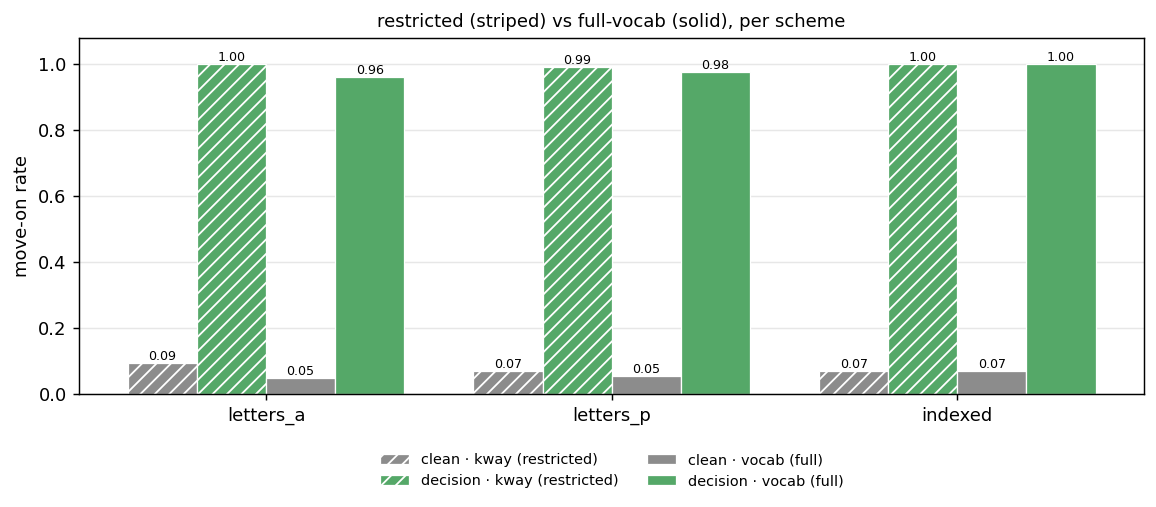

    letters_a, per transition (decision arm)    
┏━━━━━━━━━━━━┳━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━┓
┃ transition ┃  n ┃  kway ┃ vocab ┃ clean kway ┃
┡━━━━━━━━━━━━╇━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━┩
│ b->c       │ 37 │ 1.000 │ 0.973 │      0.081 │
│ c->d       │ 51 │ 1.000 │ 0.941 │      0.118 │
│ d->e       │ 40 │ 1.000 │ 0.975 │      0.075 │
└────────────┴────┴───────┴───────┴────────────┘

In [35]:
# ── §1.1 summary — each scheme against ITS OWN clean baseline ───────────────
t = Table(title=f"move-on transfer across naming schemes (one a,b,c vector, alpha={ALPHA}, N={N_OOD})")
for c in ["scheme", "arm", "kway (restricted)", "vocab (full)", "2-way", "mean margin",
          "Δ vs clean", "flip (kway)"]:
    t.add_column(c, justify="left" if c in ("scheme", "arm") else "right")
for scheme in SCHEMES:
    sub = ood_df[ood_df.scheme == scheme]
    cl = sub[sub.arm == "clean"].set_index("idx")
    for arm in ("clean", "decision"):
        g = sub[sub.arm == arm].set_index("idx")
        stayed = cl[~cl.moved_on_kway].index
        flip = float(g.loc[stayed].moved_on_kway.mean()) if len(stayed) and arm != "clean" else float("nan")
        t.add_row(f"{scheme}  (diverge@tok {int(sub.div_j.mode()[0])})" if arm == "clean" else "", arm,
                  f"{g.moved_on_kway.mean():.3f}",
                  f"{g.moved_on_vocab.mean():.3f}",
                  f"{g.moved_on_2way.mean():.3f}", f"{g.margin.mean():+.3f}",
                  "—" if arm == "clean" else f"{(g.margin - cl.margin).mean():+.3f}",
                  "—" if flip != flip else f"{flip:.3f}")
rich_print(t)
rich_print("[grey58]`vocab` is the full-vocab argmax at the first token where the CURRENT and NEXT "
           "names diverge (`diverge@tok` says which; 0 = the token right after the pivot, so for "
           "letters it is exactly 11 §4's metric). Reading it at token 0 for `indexed` scored clean "
           "at 0.953, because a multiline continuation re-assigns the current variable and so also "
           "emits ' var'. `kway` is a restricted 5-way choice and belongs with 11 §4's 1.000 "
           "(2-way), NOT its 0.977 (full-vocab).[/grey58]")

# ── what the model ACTUALLY wrote (unrestricted) ──
et = Table(title="emitted variable name — unrestricted greedy decode")
for c in ["scheme", "arm", "target", "current", "other listed", "novel", "none"]:
    et.add_column(c, justify="left" if c in ("scheme", "arm") else "right")
for scheme in SCHEMES:
    for arm in ("clean", "decision"):
        g = ood_df[(ood_df.scheme == scheme) & (ood_df.arm == arm)]
        f = g.emitted_kind.value_counts(normalize=True)
        et.add_row(scheme if arm == "clean" else "", arm,
                   *[f"{f.get(k, 0.0):.3f}" for k in ("target", "current", "other", "novel", "none")])
rich_print(et)
rich_print("[grey58]`novel` = the model wrote a name outside the candidate list. The instruction only "
           "mandates names for the `letters` schemes, so this is where a restricted argmax could be "
           "flattering `indexed`.[/grey58]")

# colour = arm, hatch = metric. `kway` is the RESTRICTED 5-way choice and is striped so it is
# never read as the same kind of number as the full-vocab bars next to it.
ARMC = {"clean": "#8c8c8c", "decision": "#55a868"}
BARS = [("clean", "moved_on_kway"), ("decision", "moved_on_kway"),
        ("clean", "moved_on_vocab"), ("decision", "moved_on_vocab")]
fig, ax = plt.subplots(figsize=(9, 4.4), dpi=130)
xs = np.arange(len(SCHEMES)); w = 0.2
for k, (arm, met) in enumerate(BARS):
    kway = met.endswith("kway")
    ys = [ood_df[(ood_df.scheme == s) & (ood_df.arm == arm)][met].mean() for s in SCHEMES]
    ax.bar(xs + k * w - 1.5 * w, ys, w, color=ARMC[arm],
           hatch="///" if kway else None, edgecolor="white", linewidth=0.7,
           label=f"{arm} · {'kway (restricted)' if kway else 'vocab (full)'}")
    for x, y in zip(xs + k * w - 1.5 * w, ys):
        ax.text(x, y, f"{y:.2f}", ha="center", va="bottom", fontsize=7)
ax.set_xticks(xs); ax.set_xticklabels(list(SCHEMES)); ax.set_ylabel("move-on rate")
ax.set_ylim(0, 1.08); ax.grid(axis="y", alpha=.3); ax.set_axisbelow(True)
ax.set_title("restricted (striped) vs full-vocab (solid), per scheme", fontsize=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False, fontsize=8)
plt.tight_layout(); fig.subplots_adjust(bottom=0.30); plt.show()

pt = Table(title="letters_a, per transition (decision arm)")
for c in ["transition", "n", "kway", "vocab", "clean kway"]:
    pt.add_column(c, justify="left" if c == "transition" else "right")
base = ood_df[ood_df.scheme == "letters_a"]
for s in SLOTS:
    d = base[(base.slot == s) & (base.arm == "decision")]
    c0 = base[(base.slot == s) & (base.arm == "clean")]
    pt.add_row(TRANS[s], str(len(d)), f"{d.moved_on_kway.mean():.3f}",
               f"{d.moved_on_vocab.mean():.3f}", f"{c0.moved_on_kway.mean():.3f}")
rich_print(pt)

## 1.2 Qualitative — natural names, and reverse execution order

Two variants where a cheap oracle is not worth building. Greedy decode under the patch, printed for
eyeballing.

**Natural names** (`is_palindrome`, `is_divisible_by_5`, …). No first-token oracle is possible — all
`is_*` names share the token `' is'` — and the K-way scorer from §1.1 would work but the names carry
semantics, so a "correct" advance is better judged by reading it.

**Reverse execution order.** Same corpus and natural names, but the prefill implements conditions
**last-to-first** and the instruction says so. This is the sharpest form of the question: the move-on
vector was cached on forward-order contexts, so does it advance to

* the **next-executed** condition (slot − 1 here) — the signal means "advance in the demonstrated
  sequence", i.e. `next()`; or
* the **next-listed** one (slot + 1) — the signal is tied to prompt order rather than execution order?

We care about next-executed throughout; the variable names are surface. Note both readings predict a
*move*, so the interesting output is **which direction**, not whether anything happened.

In [24]:
# ── natural names + reverse-order prompts (qualitative) ─────────────────────
from src.goals.goalscope import headpatched_generate
from rich.box import SIMPLE_HEAVY
from rich.text import Text
from src.goals.condition_data import (INT_PREDICATES, ConditionSample, ConditionSpec,
                                      sample_test_inputs)
from src.goals.functional import apply_chat_template

REVERSE_CLAUSE = ("The conditions should be checked in the REVERSE order of how they are mentioned "
                  "in this prompt: implement the LAST condition first and the FIRST condition last.")

def build_reverse_example(rng, target_slot, n_cond=5):
    """Prefill implements conditions last-to-first; pivot mid-implementation of `target_slot`.
    'Move on' in EXECUTION order therefore means slot-1 (next-listed would be slot+1)."""
    assert 1 <= target_slot <= n_cond - 2, "need >=1 executed prior (slot>target) and a successor"
    pool = [p for p in INT_PREDICATES if p.is_multiline_for("python")]
    preds = rng.sample(pool, n_cond)
    params = [p.sample_params(rng) for p in preds]
    var_names = [p.var_name for p in preds]
    spec = ConditionSpec(
        spec_id=f"rev_s{target_slot}_{rng.randrange(10**6):06d}",
        predicate_ids=[p.id for p in preds], predicate_params=params,
        spec_texts=[p.render(pr) for p, pr in zip(preds, params)],
        id_substrs=[p.render_substrs(pr) for p, pr in zip(preds, params)],
        test_inputs=sample_test_inputs(rng, "int"))
    sample = ConditionSample(spec=spec, lang="python", modularity="monolithic", without_comment=True)
    # priors = slots ABOVE the target, emitted descending; >=1 multiline for the usual precedent
    prior_slots = list(range(n_cond - 1, target_slot, -1))
    styles = [rng.choice(["multiline", "singleline"]) for _ in prior_slots]
    if "multiline" not in styles: styles[rng.randrange(len(styles))] = "multiline"
    body = []
    for j, st in zip(prior_slots, styles):
        p, prm, v = preds[j], params[j], var_names[j]
        body += ([p.render_singleline(prm, v, lang="python")]
                 if st == "singleline" and p.has_singleline_for("python")
                 else p.render_multiline(prm, v, lang="python"))
    tp, tprm, tvar = preds[target_slot], params[target_slot], var_names[target_slot]
    body += [tp.render_multiline(tprm, tvar, lang="python")[0]]        # incomplete -> pivot
    instr = sample.render_instruction(name_rule="free").strip() + "\n\n" + REVERSE_CLAUSE
    full = apply_chat_template(mt=mt, user_query=instr,
                               incomplete_code=sample.render_code_stub() + "\n".join(body) + "\n")
    return dict(prompt=replace_in_code_newline_with_tabnewline(full) + "   ",
                names=var_names, cur=target_slot,
                nxt_exec=target_slot - 1, nxt_listed=target_slot + 1, spec=spec)

@torch.no_grad()
def gen_arms(prompt, max_new=26, alpha=ALPHA, src=None):
    """(clean, patched) greedy continuations; the patch fires at the pivot only."""
    inp = prepare_input(prompts=prompt, tokenizer=mt)
    src = MEAN_SRC if src is None else src
    clean = headpatched_generate(mt, dict(inp), src, get_mask_bin([]), dec_layers,
                                 max_new_tokens=max_new, patch_input_positions=[PATCH_POS])
    patched = headpatched_generate(mt, dict(inp), src, DEC_MASK, dec_layers,
                                   max_new_tokens=max_new, n_steer_tokens=1,
                                   patch_input_positions=[PATCH_POS], alpha=alpha)
    return clean, patched

def show_case(title, inst):
    """Full prompt, then the clean and patched continuations side by side in one table."""
    clean, patched = gen_arms(inst["prompt"])
    names, cur = inst["names"], inst["cur"]

    rich_print(Panel(Text(inst["prompt"]), title=f"[bold]{title}[/bold]  ·  PROMPT "
                     "[grey58](instruction + code prefix, verbatim)[/grey58]",
                     title_align="left", border_style="grey42", padding=(0, 1)))

    if "nxt_exec" in inst:      # reverse-order case: the two readings disagree
        legend = (f"[bold]current[/bold] [yellow]{names[cur]}[/yellow]   ·   "
                  f"next-[bold]EXECUTED[/bold] [green]{names[inst['nxt_exec']]}[/green]   ·   "
                  f"next-[bold]LISTED[/bold] [red]{names[inst['nxt_listed']]}[/red]")
    else:
        legend = (f"[bold]current[/bold] [yellow]{names[cur]}[/yellow]   ·   "
                  f"next [green]{names[inst['nxt']]}[/green]")
    order = ", ".join(f"[yellow]{n}[/yellow]" if i == cur else n for i, n in enumerate(names))

    t = Table(title=f"{title}   ·   vars (listed order): {order}\n{legend}",
              box=SIMPLE_HEAVY, expand=True, pad_edge=False, title_justify="left")
    t.add_column("clean  (no patch)", style="sea_green3", ratio=1, overflow="fold")
    t.add_column("patched  (move-on injected)", style="salmon1", ratio=1, overflow="fold")
    t.add_row(escape(f"  \"{clean}\""), escape(f"  \"{patched}\""))
    rich_print(t)
    rich_print("")

rich_print("[bold reverse] natural variable names [/bold reverse]")
_rng = random.Random(11)
for i in range(8):
    inst = build_pivot_instance(_rng, _rng.choice(SLOTS), 5, naming="natural")
    inst["nxt"] = inst["cur"] + 1
    show_case(f"natural #{i}", inst)

rich_print("\n[bold reverse] reverse execution order (natural names) [/bold reverse]")
_rng = random.Random(23)
for i in range(8):
    show_case(f"reverse #{i}", build_reverse_example(_rng, target_slot=_rng.choice([1, 2, 3])))

 natural variable names 

╭─ natural #0  ·  PROMPT (instruction + code prefix, verbatim) ───────────────────────────────────────────────────╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `check_conditions` which, given an integer n, checks the      │
│ following conditions:                                                                                           │
│                                                                                                                 │
│ 1. the sum of n's proper divisors is greater than n                                                             │
│ 2. the product of n's digits is greater than 20                                                                 │
│ 3. n is a prime number                                                                                          │
│ 4. n is a palindrome (its digits read the same forwards and backwards)                                          │
│ 5. n is divisible by 7                                                                                          │
│                                                                                                                 │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable.      │
│ After all conditions have been checked, use a SINGLE print statement that, using those variables, reports       │
│ whether each condition passed individually and whether all of them passed collectively.                         │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.                                                                                    │
│ Do not include any comments in your code.<|im_end|>                                                             │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def check_conditions(n: int):                                                                                   │
│     is_abundant = sum(d for d in range(1, abs(n)) if n % d == 0)                                                │
│     is_abundant = n > 0 and is_abundant > n                                                                     │
│     has_large_digit_product = math.prod(int(d) for d in str(abs(n))) > 20                                       │
│     is_prime = all(n % d != 0 for d in range(2, int(abs(n) ** 0.5) + 1))                                        │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

natural #0   ·   vars (listed order): is_abundant, has_large_digit_product, is_prime, is_palindrome, is_divisible  
current is_prime   ·   next is_palindrome                                                                          
                                                                                                                   
 clean  (no patch)                                         patched  (move-on injected)                             
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
   " is_prime = n > 1 and is_prime                           " is_palindrome = str(n) == str(n)[::-1]              
     is_palindrome = str(n) == str(n)[::-1]"                   is_divisible_by_seven = n %"                       

╭─ natural #1  ·  PROMPT (instruction + code prefix, verbatim) ───────────────────────────────────────────────────╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `check_conditions` which, given an integer n, checks the      │
│ following conditions:                                                                                           │
│                                                                                                                 │
│ 1. n is a triangular number                                                                                     │
│ 2. n is even                                                                                                    │
│ 3. n has more than 2 divisors                                                                                   │
│ 4. n is divisible by 8                                                                                          │
│ 5. the sum of n's proper divisors is greater than n                                                             │
│                                                                                                                 │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable.      │
│ After all conditions have been checked, use a SINGLE print statement that, using those variables, reports       │
│ whether each condition passed individually and whether all of them passed collectively.                         │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.                                                                                    │
│ Do not include any comments in your code.<|im_end|>                                                             │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def check_conditions(n: int):                                                                                   │
│     is_triangular = n >= 0 and int((8 * n + 1) ** 0.5) ** 2 == 8 * n + 1                                        │
│     is_even = n % 2                                                                                             │
│     is_even = is_even == 0                                                                                      │
│     has_many_divisors = sum(1 for d in range(1, abs(n) + 1) if n % d == 0)                                      │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

natural #1   ·   vars (listed order): is_triangular, is_even, has_many_divisors, is_divisible, is_abundant         
current has_many_divisors   ·   next is_divisible                                                                  
                                                                                                                   
 clean  (no patch)                                         patched  (move-on injected)                             
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
   " has_many_divisors = has_many_divisors > 2               " divisible_by_8 = n % 8 == 0                         
     divisible_by_8 = n % 8 == 0"                              sum_of_divisors = sum(d for d in range("           

╭─ natural #2  ·  PROMPT (instruction + code prefix, verbatim) ───────────────────────────────────────────────────╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `check_conditions` which, given an integer n, checks the      │
│ following conditions:                                                                                           │
│                                                                                                                 │
│ 1. n is smaller than the number obtained by reversing its digits                                                │
│ 2. n has more than 1 ones in its binary representation                                                          │
│ 3. all of n's digits are even                                                                                   │
│ 4. n is even                                                                                                    │
│ 5. n is a power of two                                                                                          │
│                                                                                                                 │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable.      │
│ After all conditions have been checked, use a SINGLE print statement that, using those variables, reports       │
│ whether each condition passed individually and whether all of them passed collectively.                         │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.                                                                                    │
│ Do not include any comments in your code.<|im_end|>                                                             │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def check_conditions(n: int):                                                                                   │
│     is_reverse_greater = int(str(abs(n))[::-1])                                                                 │
│     is_reverse_greater = is_reverse_greater > abs(n)                                                            │
│     has_many_set_bits = bin(abs(n)).count("1") > 1                                                              │
│     all_digits_even = all(int(c) % 2 == 0 for c in str(abs(n)))                                                 │
│     is_even = n % 2                                                                                             │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

... (24 outputs left out)

╭─ reverse #6  ·  PROMPT (instruction + code prefix, verbatim) ───────────────────────────────────────────────────╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `check_conditions` which, given an integer n, checks the      │
│ following conditions:                                                                                           │
│                                                                                                                 │
│ 1. the product of n's digits is greater than 20                                                                 │
│ 2. n is divisible by 17                                                                                         │
│ 3. n is coprime with 10                                                                                         │
│ 4. n is even                                                                                                    │
│ 5. the sum of n's digits is greater than 5                                                                      │
│                                                                                                                 │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable.      │
│ After all conditions have been checked, use a SINGLE print statement that, using those variables, reports       │
│ whether each condition passed individually and whether all of them passed collectively.                         │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.                                                                                    │
│ Do not include any comments in your code.                                                                       │
│                                                                                                                 │
│ The conditions should be checked in the REVERSE order of how they are mentioned in this prompt: implement the   │
│ LAST condition first and the FIRST condition last.<|im_end|>                                                    │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def check_conditions(n: int):                                                                                   │
│     has_large_digit_sum = sum(int(d) for d in str(abs(n)))                                                      │
│     has_large_digit_sum = has_large_digit_sum > 5                                                               │
│     is_even = n % 2                                                                                             │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

reverse #6   ·   vars (listed order): has_large_digit_product, is_divisible, is_coprime, is_even,                  
has_large_digit_sum                                                                                                
current is_even   ·   next-EXECUTED is_coprime   ·   next-LISTED has_large_digit_sum                               
                                                                                                                   
 clean  (no patch)                                         patched  (move-on injected)                             
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
   " is_even = is_even == 0                                  " is_coprime_with_10 = n % 2 != 0 and n % 5 != 0"     
     is_coprime_with_10 = n % 10"                                                                                 

╭─ reverse #7  ·  PROMPT (instruction + code prefix, verbatim) ───────────────────────────────────────────────────╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `check_conditions` which, given an integer n, checks the      │
│ following conditions:                                                                                           │
│                                                                                                                 │
│ 1. n is divisible by 19                                                                                         │
│ 2. n is a perfect square                                                                                        │
│ 3. n has more than 3 divisors                                                                                   │
│ 4. n is a triangular number                                                                                     │
│ 5. n is coprime with 12                                                                                         │
│                                                                                                                 │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable.      │
│ After all conditions have been checked, use a SINGLE print statement that, using those variables, reports       │
│ whether each condition passed individually and whether all of them passed collectively.                         │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.                                                                                    │
│ Do not include any comments in your code.                                                                       │
│                                                                                                                 │
│ The conditions should be checked in the REVERSE order of how they are mentioned in this prompt: implement the   │
│ LAST condition first and the FIRST condition last.<|im_end|>                                                    │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def check_conditions(n: int):                                                                                   │
│     is_coprime = math.gcd(n, 12) == 1                                                                           │
│     is_triangular = n >= 0 and int((8 * n + 1) ** 0.5) ** 2 == 8 * n + 1                                        │
│     has_many_divisors = sum(1 for d in range(1, abs(n) + 1) if n % d == 0)                                      │
│     has_many_divisors = has_many_divisors > 3                                                                   │
│     is_perfect_square = int(abs(n) ** 0.5)                                                                      │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

reverse #7   ·   vars (listed order): is_divisible, is_perfect_square, has_many_divisors, is_triangular, is_coprime
current is_perfect_square   ·   next-EXECUTED is_divisible   ·   next-LISTED has_many_divisors                     
                                                                                                                   
 clean  (no patch)                                         patched  (move-on injected)                             
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
   " is_perfect_square = is_perfect_square *                 " is_divisible_by_19 = n % 19 == 0                    
 is_perfect_square == abs(n)                                   print(f"Divisible by 1"                             
     is_divisible_by_1"                                                                                           

## 2. `next()` or program counter — does a bigger α skip further?

A program counter can be set to any address; `next()` can only advance by one. If the move-on signal
is `next()`, scaling α should *saturate* at the immediate successor — stronger push, same
destination, eventually degenerate output. If it is a pointer with a magnitude, a bigger push should
land further along (`c` or `d` instead of `b`).

Qualitative, 2–3 examples. Read the destination letter, not the fluency.

In [19]:
# ── α sweep (qualitative) ───────────────────────────────────────────────────
# NOTE: the transplant is  alpha*mask*src + (1-mask)*cascade, so with mask=1 at the selected heads
# alpha=0 ZEROES them — that is an ablation, not a baseline. The clean row uses an EMPTY mask
# (mask=0 everywhere -> pure cascade), which is the real no-intervention control.
ALPHAS = [0.5, 1.0, 2.0, 4.0, 8.0, 16.0, 32.0]
_rng = random.Random(101)
for i in range(5):
    inst = build_pivot_instance(_rng, _rng.choice(SLOTS), 5, naming="letters")
    inp = prepare_input(prompts=inst["prompt"], tokenizer=mt)
    rich_print(Panel(Text(inst["prompt"]), title=f"[bold]alpha sweep #{i}[/bold]  ·  PROMPT",
                     title_align="left", border_style="grey42", padding=(0, 1)))
    rows = [("clean", headpatched_generate(mt, dict(inp), MEAN_SRC, get_mask_bin([]), dec_layers,
                                           max_new_tokens=22, patch_input_positions=[PATCH_POS]))]
    rows += [(f"{a:g}", headpatched_generate(mt, dict(inp), MEAN_SRC, DEC_MASK, dec_layers,
                                             max_new_tokens=22, n_steer_tokens=1,
                                             patch_input_positions=[PATCH_POS], alpha=a))
             for a in ALPHAS]
    t = Table(title=f"current [yellow]{inst['names'][inst['cur']]}[/yellow]  ·  successor "
                    f"[green]{inst['names'][inst['nxt']]}[/green]  ·  vars {inst['names']}",
              box=SIMPLE_HEAVY, expand=True, pad_edge=False, title_justify="left")
    t.add_column("alpha", justify="right", no_wrap=True)
    t.add_column("continuation", overflow="fold", ratio=1)
    for a, g in rows:
        t.add_row(a, Text("   " + g, style="sea_green3" if a == "clean" else "salmon1"))
    rich_print(t); rich_print("")
rich_print("[grey58]Saturating at the immediate successor as alpha grows = next(). Marching further "
           "down the list with alpha = a pointer with magnitude.[/grey58]")

╭─ alpha sweep #0  ·  PROMPT ─────────────────────────────────────────────────────────────────────────────────────╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `check_conditions` which, given an integer n, checks the      │
│ following conditions:                                                                                           │
│                                                                                                                 │
│ 1. n is a palindrome (its digits read the same forwards and backwards)                                          │
│ 2. the sum of n's proper divisors is greater than n                                                             │
│ 3. n is coprime with 10                                                                                         │
│ 4. the product of n's digits is greater than 5                                                                  │
│ 5. n is even                                                                                                    │
│                                                                                                                 │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable,      │
│ using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all │
│ conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each    │
│ condition passed individually and whether all of them passed collectively.                                      │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.                                                                                    │
│ Do not include any comments in your code.<|im_end|>                                                             │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def check_conditions(n: int):                                                                                   │
│     a = str(abs(n)) == str(abs(n))[::-1]                                                                        │
│     b = sum(d for d in range(1, abs(n)) if n % d == 0)                                                          │
│     b = n > 0 and b > n                                                                                         │
│     c = math.gcd(n, 10) == 1                                                                                    │
│     d = 1                                                                                                       │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

current d  ·  successor e  ·  vars ['a', 'b', 'c', 'd', 'e']                                                       
                                                                                                                   
 alpha   continuation                                                                                              
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 clean       for digit in str(abs(n)):                                                                             
                 d *= int(digit)                                                                                   
             d = d >                                                                                               
   0.5       for digit in str(abs(n)):                                                                             
                 d *= int(digit)                                                                                   
             d = d >                                                                                               
     1       for digit in str(abs(n)):                                                                             
                 d *= int(digit)                                                                                   
             d = d >                                                                                               
     2       e = n % 2 == 0                                                                                        
             print(f"a: {a}, b: {b                                                                                 
     4       e = all(int(d) > 0 for d in str(abs(n))) and eval('*'.join(str                                        
     8       for digit in str(abs(n)):                                                                             
                 d *= int(digit)                                                                                   
             d = d >                                                                                               
    16       for digit in str(abs(n)): d *= int(digit); d = d > 5                                                  
             e                                                                                                     
    32       for digit in str(abs(n)): d *= int(digit) > 0 and int(digit) >                                       

╭─ alpha sweep #1  ·  PROMPT ─────────────────────────────────────────────────────────────────────────────────────╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `check_conditions` which, given an integer n, checks the      │
│ following conditions:                                                                                           │
│                                                                                                                 │
│ 1. n is a triangular number                                                                                     │
│ 2. n is divisible by 17                                                                                         │
│ 3. the product of n's digits is greater than 10                                                                 │
│ 4. n is coprime with 10                                                                                         │
│ 5. n is a perfect square                                                                                        │
│                                                                                                                 │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable,      │
│ using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all │
│ conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each    │
│ condition passed individually and whether all of them passed collectively.                                      │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.                                                                                    │
│ Do not include any comments in your code.<|im_end|>                                                             │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def check_conditions(n: int):                                                                                   │
│     a = int((2 * abs(n)) ** 0.5)                                                                                │
│     a = n >= 0 and a * (a + 1) // 2 == n                                                                        │
│     b = n % 17                                                                                                  │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

current b  ·  successor c  ·  vars ['a', 'b', 'c', 'd', 'e']                                                       
                                                                                                                   
 alpha   continuation                                                                                              
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 clean       b = b == 0                                                                                            
             c = 1                                                                                                 
             for d in str(n):                                                                                      
   0.5       c = 1                                                                                                 
             for d in str(n):                                                                                      
                 c *= int(d)                                                                                       
             c                                                                                                     
     1       c = 1                                                                                                 
             for d in str(n):                                                                                      
                 c *= int(d)                                                                                       
             c                                                                                                     
     2       c = 1                                                                                                 
             for d in str(n):                                                                                      
                 c *= int(d)                                                                                       
             c                                                                                                     
     4       c = 1                                                                                                 
             for d in str(n):                                                                                      
                 c *= int(d)                                                                                       
             c                                                                                                     
     8       c = 1                                                                                                 
             for d in str(n):                                                                                      
                 c *= int(d)                                                                                       
             c                                                                                                     
    16       c = 1                                                                                                 
             for d in str(n):                                                                                      
                 c *= int(d)                                                                                       
             c                                                                                                     
    32       c = 1                                                                                                 
             for d in str(n): c *= int(d)                                                                          
             c = c                                                                                                

╭─ alpha sweep #2  ·  PROMPT ─────────────────────────────────────────────────────────────────────────────────────╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `check_conditions` which, given an integer n, checks the      │
│ following conditions:                                                                                           │
│                                                                                                                 │
│ 1. n is a perfect square                                                                                        │
│ 2. n is a power of two                                                                                          │
│ 3. n has at least 3 digits                                                                                      │
│ 4. the sum of n's digits is greater than 10                                                                     │
│ 5. all of n's digits are even                                                                                   │
│                                                                                                                 │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable,      │
│ using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all │
│ conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each    │
│ condition passed individually and whether all of them passed collectively.                                      │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.                                                                                    │
│ Do not include any comments in your code.<|im_end|>                                                             │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def check_conditions(n: int):                                                                                   │
│     a = int(abs(n) ** 0.5)                                                                                      │
│     a = n >= 0 and a * a == n                                                                                   │
│     b = bin(n).count("1")                                                                                       │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

current b  ·  successor c  ·  vars ['a', 'b', 'c', 'd', 'e']                                                       
                                                                                                                   
 alpha   continuation                                                                                              
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 clean       b = n > 0 and b == 1                                                                                  
             c = len(str(n)) >= 3                                                                                  
   0.5       c = n >= 100                                                                                          
             d = sum(int(digit) for digit in str(n                                                                 
     1       c = n >= 100                                                                                          
             d = sum(int(digit) for digit in str(n                                                                 
     2       c = n >= 100                                                                                          
             d = sum(int(digit) for digit in str(n                                                                 
     4       c = n >= 100                                                                                          
             d = sum(int(digit) for digit in str(n                                                                 
     8       c = n >= 100                                                                                          
             d = sum(int(digit) for digit in str(n                                                                 
    16       c = n >= 100                                                                                          
             d = sum(int(digit) for digit in str(n                                                                 
    32       c = n >= 100                                                                                          
             d = sum(int(digit) for digit in str(n                                                                

╭─ alpha sweep #3  ·  PROMPT ─────────────────────────────────────────────────────────────────────────────────────╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `check_conditions` which, given an integer n, checks the      │
│ following conditions:                                                                                           │
│                                                                                                                 │
│ 1. n is a perfect square                                                                                        │
│ 2. n is coprime with 12                                                                                         │
│ 3. n is even                                                                                                    │
│ 4. the sum of n's proper divisors is greater than n                                                             │
│ 5. all of n's digits are even                                                                                   │
│                                                                                                                 │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable,      │
│ using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all │
│ conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each    │
│ condition passed individually and whether all of them passed collectively.                                      │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.                                                                                    │
│ Do not include any comments in your code.<|im_end|>                                                             │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def check_conditions(n: int):                                                                                   │
│     a = int(abs(n) ** 0.5)                                                                                      │
│     a = n >= 0 and a * a == n                                                                                   │
│     b = math.gcd(n, 12) == 1                                                                                    │
│     c = n % 2                                                                                                   │
│     c = c == 0                                                                                                  │
│     d = sum(d for d in range(1, abs(n)) if n % d == 0)                                                          │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

current d  ·  successor e  ·  vars ['a', 'b', 'c', 'd', 'e']                                                       
                                                                                                                   
 alpha   continuation                                                                                              
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 clean       d = d > n                                                                                             
             e = all(int(digit) % 2 == 0 for digit                                                                 
   0.5       e = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             print                                                                                                 
     1       e = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             print                                                                                                 
     2       e = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             print                                                                                                 
     4       e = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             print                                                                                                 
     8       e = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             print                                                                                                 
    16       e = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             print                                                                                                 
    32       e = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             print                                                                                                

╭─ alpha sweep #4  ·  PROMPT ─────────────────────────────────────────────────────────────────────────────────────╮
│ <|im_start|>system                                                                                              │
│ You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical   │
│ correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>                              │
│ <|im_start|>user                                                                                                │
│ Write a Python program that implements a function `check_conditions` which, given an integer n, checks the      │
│ following conditions:                                                                                           │
│                                                                                                                 │
│ 1. the sum of n's digits is greater than 15                                                                     │
│ 2. n is coprime with 10                                                                                         │
│ 3. all of n's digits are even                                                                                   │
│ 4. n is a triangular number                                                                                     │
│ 5. n is smaller than the number obtained by reversing its digits                                                │
│                                                                                                                 │
│ For each condition, in the order listed, assign the boolean result of the check to its own local variable,      │
│ using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all │
│ conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each    │
│ condition passed individually and whether all of them passed collectively.                                      │
│ Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not    │
│ define any helper functions.                                                                                    │
│ Do not include any comments in your code.<|im_end|>                                                             │
│ <|im_start|>assistant                                                                                           │
│ <code>                                                                                                          │
│ def check_conditions(n: int):                                                                                   │
│     a = sum(int(d) for d in str(abs(n)))                                                                        │
│     a = a > 15                                                                                                  │
│     b = math.gcd(n, 10)                                                                                         │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

current b  ·  successor c  ·  vars ['a', 'b', 'c', 'd', 'e']                                                       
                                                                                                                   
 alpha   continuation                                                                                              
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
 clean       b = b == 1                                                                                            
             c = all(int(d) % 2 == 0 for d                                                                         
   0.5       c = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             d                                                                                                     
     1       c = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             d                                                                                                     
     2       c = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             d                                                                                                     
     4       c = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             d                                                                                                     
     8       c = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             d                                                                                                     
    16       c = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             d                                                                                                     
    32       c = all(int(d) % 2 == 0 for d in str(abs(n)))                                                         
             d                                                                                                    

Saturating at the immediate successor as alpha grows = next(). Marching further down the list with alpha = a 
pointer with magnitude.

## 3. Does the *fetch* actually happen?

`11 §4`'s 0.977 says the model emits the next **variable letter**. It does not say the model then
implements that condition — "the pointer advanced", not "the right instruction was fetched". The
whole `next()` reading rests on advance-then-resolve, so this is the gap that matters most.

**Oracle eval.** Greedy-decode under the move-on patch, strip the generated right-hand side, and ask
the judge — once per condition — whether that stub attempts it. K judgements per prompt, so the
answer is not just "does it match the target" but "does it match *anything else*".

**Success = exactly one YES, and that YES is the TARGET.** Two YES verdicts is not a success even if
one of them is the target: it means the stub is ambiguous between conditions, which for a
`d = a and c`-style aggregate is a real possibility. Zero YES means the advance produced content that
implements nothing — a pointer that moved without a fetch.

In [23]:
# ── §3: after a move-on patch, is the CONTENT the next condition? (oracle) ──
from src.utils.oracle_llms import ask_claude
from src.goals.condition_data import INT_PREDICATES

N_FETCH = 10
ORACLE_SYS = (
    "You are a meticulous code reviewer. You are shown ONE natural-language condition and ONE "
    "short Python stub (the right-hand side of an assignment, possibly incomplete). Decide whether "
    "the stub is a genuine attempt to implement THAT condition.\n"
    "Answer with exactly one token:\n"
    "  YES        — implements or clearly attempts the condition, even with minor bugs.\n"
    "  NO         — well-formed but implements a DIFFERENT condition.\n"
    "  MALFORMED  — degenerate, expresses no coherent check at all."
)

def oracle_kway(spec, stub):
    out = []
    for txt in spec.spec_texts:
        r = ask_claude(f"Condition: {txt}\nCode stub: {stub}\nAnswer:", use_cache=True,
                       max_tokens=8, system_prompt=ORACLE_SYS).strip().upper()
        out.append("YES" if r.startswith("YES") else ("MALF" if r.startswith("MAL") else "NO"))
    return out

def split_generation(gen):
    """(emitted_var, rhs_stub) from the first generated line. If the model stayed on the current
    condition there is no new assignment, so the whole line is handed over as the stub."""
    line = gen.split("\n")[0].strip()
    if "=" in line and not line.startswith("="):
        var, rhs = line.split("=", 1)
        return var.strip(), rhs.strip()
    return None, line

def show_prefix_with_pivot(prompt, title):
    """Code prefix with the intervention token marked in place."""
    ids = mt.tokenizer(prompt, add_special_tokens=False)["input_ids"]
    piv = len(ids) + PATCH_POS                       # PATCH_POS is end-relative
    pre = mt.tokenizer.decode(ids[:piv]).replace("\n", "↵\n").replace(" ", ".")
    tok = mt.tokenizer.decode(ids[piv:piv + 1]).replace("\n", "↵\n").replace(" ", ".")
    post = mt.tokenizer.decode(ids[piv + 1:]).replace("\n", "↵\n").replace(" ", ".")
    pre = pre.split("<code>")[-1]                    # drop the instruction, keep the code
    body = Text(pre, style="white")
    body.append(f"«{tok}»", style="bold black on yellow")
    body.append(post, style="white")
    rich_print(Panel(body, title=title, title_align="left", border_style="grey42", padding=(0, 1)))

_rng = random.Random(77)
n_success = 0
for i in range(N_FETCH):
    inst = build_pivot_instance(_rng, _rng.choice(SLOTS), 5, naming="letters")
    spec, names, cur, nxt = inst["spec"], inst["names"], inst["cur"], inst["nxt"]

    # 1 ── the conditions, CURRENT and TARGET marked
    ct = Table(title=f"[bold]#{i}[/bold]  ·  conditions", box=SIMPLE_HEAVY, expand=True,
               pad_edge=False, title_justify="left")
    for c_ in ["k", "var", "condition", ""]:
        ct.add_column(c_, justify="right" if c_ == "k" else "left", overflow="fold")
    for k, txt in enumerate(spec.spec_texts):
        if k == cur:   sty, tag = "bold yellow", "CURRENT (being implemented)"
        elif k == nxt: sty, tag = "bold green",  "TARGET (move-on destination)"
        else:          sty, tag = "grey58", ""
        ct.add_row(Text(str(k), style=sty), Text(names[k], style=sty),
                   Text(txt, style=sty), Text(tag, style=sty))
    rich_print(ct)

    # 2 ── the code prefix with the intervention position marked
    show_prefix_with_pivot(inst["prompt"],
                           f"code prefix  ·  [bold black on yellow]«…»[/bold black on yellow] "
                           f"= intervention token (PATCH_POS={PATCH_POS})")

    # 3 ── patched generation
    _, patched = gen_arms(inst["prompt"], max_new=28)
    rich_print(Panel(Text(patched.strip(), style="salmon1"),
                     title="patched generation (move-on injected)", title_align="left",
                     border_style="salmon1", padding=(0, 1)))

    # 4 ── what the oracle saw, and its K-way verdict
    emitted_var, stub = split_generation(patched)
    verds = oracle_kway(spec, stub)
    yes = [k for k, v in enumerate(verds) if v == "YES"]
    ok = (len(yes) == 1 and yes[0] == nxt)
    n_success += int(ok)

    ot = Table(title=f"oracle k-way  ·  stub passed in: [salmon1]{escape(repr(stub))}[/salmon1]"
                     f"  ·  emitted var: [salmon1]{emitted_var}[/salmon1]",
               box=SIMPLE_HEAVY, expand=True, pad_edge=False, title_justify="left")
    for c_ in ["k", "var", "condition", "verdict"]:
        ot.add_column(c_, justify="right" if c_ == "k" else "left", overflow="fold")
    for k, txt in enumerate(spec.spec_texts):
        sty = "bold green" if k == nxt else ("bold yellow" if k == cur else "grey58")
        vs = {"YES": "bold green", "MALF": "bold magenta"}.get(verds[k], "grey58")
        ot.add_row(Text(str(k), style=sty), Text(names[k], style=sty), Text(txt, style=sty),
                   Text(verds[k], style=vs))
    rich_print(ot)
    rich_print(Panel(
        Text.from_markup(
            f"YES on {[names[k] for k in yes] or '—'}   ·   TARGET = [green]{names[nxt]}[/green]   "
            f"·   " + ("[bold green]INTERVENTION SUCCESS[/bold green]" if ok else
                       "[bold red]not a success[/bold red] " +
                       ("(no condition matched)" if not yes else
                        "(ambiguous — multiple YES)" if len(yes) > 1 else
                        f"(matched {names[yes[0]]}, not the target)"))),
        border_style="green" if ok else "red", padding=(0, 1)))
    rich_print("")

rich_print(f"[bold]fetch success: {n_success}/{N_FETCH}[/bold] "
           f"[grey58](exactly one YES, and it is the TARGET)[/grey58]")

#0  ·  conditions                                                                                                  
                                                                                                                   
  k   var    condition                                                                                             
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  0   a      n is a power of two                                                                                   
  1   b      n is a palindrome (its digits read the same forwards and backwards)                                   
  2   c      n is smaller than the number obtained by reversing its digits            CURRENT (being implemented)  
  3   d      the sum of n's proper divisors is greater than n                         TARGET (move-on destination) 
  4   e      the sum of n's digits is divisible by 3                                                              

╭─ code prefix  ·  «…» = intervention token (PATCH_POS=-2) ───────────────────────────────────────────────────────╮
│ ....↵                                                                                                           │
│ def.check_conditions(n:.int):....↵                                                                              │
│ ....a.=.bin(n).count("1")....↵                                                                                  │
│ ....a.=.n.>.0.and.a.==.1....↵                                                                                   │
│ ....b.=.str(abs(n)).==.str(abs(n))[::-1]....↵                                                                   │
│ ....c.=.int(str(abs(n))[::-1])«....↵                                                                            │
│ »...                                                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ patched generation (move-on injected) ─────────────────────────────────────────────────────────────────────────╮
│ d = sum(i for i in range(1, n) if n % i == 0) > n                                                               │
│     e = sum                                                                                                     │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

oracle k-way  ·  stub passed in: 'sum(i for i in range(1, n) if n % i == 0) > n'  ·  emitted var: d                
                                                                                                                   
  k   var     condition                                                                                  verdict   
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  0   a       n is a power of two                                                                        NO        
  1   b       n is a palindrome (its digits read the same forwards and backwards)                        NO        
  2   c       n is smaller than the number obtained by reversing its digits                              NO        
  3   d       the sum of n's proper divisors is greater than n                                           YES       
  4   e       the sum of n's digits is divisible by 3                                                    NO       

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ YES on ['d']   ·   TARGET = d   ·   INTERVENTION SUCCESS                                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

#1  ·  conditions                                                                                                  
                                                                                                                   
  k   var    condition                                                                                             
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  0   a      all of n's digits are even                                                                            
  1   b      n is a triangular number                                                 CURRENT (being implemented)  
  2   c      n is a palindrome (its digits read the same forwards and backwards)      TARGET (move-on destination) 
  3   d      the sum of n's digits is greater than 15                                                              
  4   e      n is divisible by 12                                                                                 

... (41 outputs left out)

╭─ patched generation (move-on injected) ─────────────────────────────────────────────────────────────────────────╮
│ c = n > 1 and all(n % i for i in range(2, int(n ** 0.5) +                                                       │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

oracle k-way  ·  stub passed in: 'n > 1 and all(n % i for i in range(2, int(n ** 0.5) +'  ·  emitted var: c        
                                                                                                                   
      k   var              condition                                                       verdict                 
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
      0   a                n is even                                                       NO                      
      1   b                n is a perfect cube                                             NO                      
      2   c                n is a prime number                                             YES                     
      3   d                n is divisible by 5                                             NO                      
      4   e                n is a power of two                                             NO                     

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ YES on ['c']   ·   TARGET = c   ·   INTERVENTION SUCCESS                                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

fetch success: 9/10 (exactly one YES, and it is the TARGET)